# Hospital OPD Time Series Analysis and Forecasting

## Project question
How can historical outpatient department (OPD) demand help a hospital understand weekly patterns and plan near-term patient capacity?

## Objectives
- Aggregate visit records into daily total and department patient counts.
- Explore data quality, trend, weekday patterns, and stationarity.
- Compare classical forecasting models using a chronological test period and MAE, RMSE, and MAPE.
- Forecast near-term demand and interpret the result for hospital planning.

## Dataset
The supplied CSV contains 52,343 records from 2024-04-19 to 2025-04-18, six departments, and a `patient_count` field. We sum that field by date and department to create 365 daily observations.

## How this notebook covers the project requirements
- **EDA and preprocessing:** Sections 3-8.
- **Classical model comparison and metrics:** Sections 9-10.
- **Multivariate VAR and VARIMA:** Section 11.
- **Future forecast and domain interpretation:** Sections 12 and 15.
- **Library requirements:** Section 13 demonstrates TSFresh, Prophet, and Darts when installed; AutoTS is included as a required automatic model search.

The first 80% of dates are used for training and the final 20% for testing. Every holdout forecast uses training data only. MAPE is computed over non-zero actual values.

## Before running
Open this notebook with its containing project folder as the Jupyter working directory. The supplied CSV is in `data/opd_data.csv`. Run cells from top to bottom. If an optional library is unavailable, its section reports that clearly; AutoTS is a required supplemental section and should be run for the final demonstration.

## 1. Imports and project folders

In [26]:
import warnings
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX

warnings.filterwarnings("ignore", category=UserWarning)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
FORECAST_DIR = OUTPUT_DIR / "forecasts"
for folder in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR, FORECAST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR.resolve())

Project folder: C:\Users\YASH BANSAL\Documents\ChatGPT\Time Series\Hospital_OPD_Time_Series_Analysis


## 2. Confirmed dataset settings
The dataset schema has been checked: `date` is the day, `department` identifies the clinic, and `patient_count` is the count to sum. The holiday status is available for the historical test period and is used as the ARIMAX regressor.

In [27]:
# Main settings used throughout the notebook.
CSV_PATH = Path("data/opd_data.csv")
DATE_COL = "date"
DEPARTMENT_COL = "department"
COUNT_COL = "patient_count"

TEST_SIZE = 0.20
FORECAST_HORIZON = 30
SEASONAL_PERIOD = 7  # One week in daily data.
FREQUENCY = "D"

## 3. Load data and inspect its structure

In [28]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}. Place opd_data.csv inside a 'data' folder "
        "or update CSV_PATH to the correct file."
    )

df_raw = pd.read_csv(CSV_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("\\nColumns:")
print(df_raw.columns.tolist())
display(df_raw.dtypes.to_frame("dtype"))

Shape: (52343, 6)


,date,day_of_week,hour,department,is_holiday,patient_count
0,2024-04-19,Friday,8,Cardiology,open,23
1,2024-04-19,Friday,8,Cardiology,open,22
2,2024-04-19,Friday,9,Cardiology,open,76
3,2024-04-19,Friday,9,Cardiology,open,49
4,2024-04-19,Friday,9,Cardiology,open,84


\nColumns:
['date', 'day_of_week', 'hour', 'department', 'is_holiday', 'patient_count']


,dtype
date,object
day_of_week,object
hour,int64
department,object
is_holiday,object
patient_count,int64


In [29]:
# Parse the ISO dates, retain valid nonnegative patient counts, and standardize department labels.
df = df_raw.copy()
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[DEPARTMENT_COL] = df[DEPARTMENT_COL].astype("string").str.strip()
df["_patient_count"] = pd.to_numeric(df[COUNT_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL, DEPARTMENT_COL, "_patient_count"]).copy()
df = df[(df[DEPARTMENT_COL] != "") & (df["_patient_count"] >= 0)].copy()
if EXPECTED_DEPARTMENTS is not None:
    df = df[df[DEPARTMENT_COL].isin(EXPECTED_DEPARTMENTS)].copy()

print("Cleaned records:", len(df))
print("Date range:", df[DATE_COL].min().date(), "to", df[DATE_COL].max().date())
print("Departments:", sorted(df[DEPARTMENT_COL].unique()))
display(df.head())


Cleaned records: 52343
Date range: 2024-04-19 to 2025-04-18
Departments: ['Cardiology', 'Dermatology', 'General Medicine', 'Neurology', 'Orthopedics', 'Pediatrics']


,date,day_of_week,hour,department,is_holiday,patient_count,_patient_count
0,2024-04-19,Friday,8,Cardiology,open,23,23
1,2024-04-19,Friday,8,Cardiology,open,22,22
2,2024-04-19,Friday,9,Cardiology,open,76,76
3,2024-04-19,Friday,9,Cardiology,open,49,49
4,2024-04-19,Friday,9,Cardiology,open,84,84


## 4. Data quality checks

In [30]:
quality = {
    "raw_rows": len(df_raw),
    "clean_rows": len(df),
    "invalid_date_rows_in_raw": int(pd.to_datetime(df_raw[DATE_COL], errors="coerce").isna().sum()),
    "exact_duplicate_rows_after_cleaning": int(df.duplicated().sum()),
    "missing_department_after_cleaning": int(df[DEPARTMENT_COL].isna().sum()),
    "negative_count_rows_in_raw": int((pd.to_numeric(df_raw[COUNT_COL], errors="coerce") < 0).sum()),
    "missing_count_rows_in_raw": int(pd.to_numeric(df_raw[COUNT_COL], errors="coerce").isna().sum()),
}
quality_df = pd.DataFrame([quality])
display(quality_df)
quality_df.to_csv(TABLE_DIR / "data_quality_summary.csv", index=False)

# Exact duplicate rows are reported for investigation, not deleted automatically.
# The CSV contains hourly/department count records; repeated-looking rows may represent legitimate counts.


,raw_rows,clean_rows,invalid_date_rows_in_raw,exact_duplicate_rows_after_cleaning,missing_department_after_cleaning,negative_count_rows_in_raw,missing_count_rows_in_raw
0,52343,52343,0,1352,0,0,0


## 5. Create daily time series
**What this does:** adds together the patient counts for each day and department, fills missing calendar dates with zero, then sums departments for the total OPD series. The holiday flag is kept separately for the ARIMAX model.

In [31]:
# Sum patient counts for each date and department.
daily_dept = (
    df.groupby([pd.Grouper(key=DATE_COL, freq="D"), DEPARTMENT_COL])["_patient_count"]
      .sum().unstack(fill_value=0).sort_index()
)

# Missing calendar dates are treated as zero visits; verify this with the data source.
full_dates = pd.date_range(daily_dept.index.min(), daily_dept.index.max(), freq="D")
daily_dept = daily_dept.reindex(full_dates, fill_value=0)
daily_dept.index.name = "date"
daily_total = daily_dept.sum(axis=1).rename("total_patients")

# The source has one holiday status per date. Encode holiday as 1 and open as 0.
holiday_daily = (
    df.assign(_holiday=df["is_holiday"].astype(str).str.lower().eq("holiday").astype(int))
      .groupby(DATE_COL)["_holiday"].max()
      .reindex(full_dates, fill_value=0)
      .rename("is_holiday")
)

# Save the processed series used in the analysis.
daily_dept.to_csv(TABLE_DIR / "daily_department_counts.csv")
daily_total.to_frame().to_csv(TABLE_DIR / "daily_total_counts.csv")
display(daily_total.head())
display(daily_dept.head())
print("Daily observations:", len(daily_total))
print("Total equals sum of departments:", bool(np.allclose(daily_total, daily_dept.sum(axis=1))))

date
2024-04-19     6982
2024-04-20     6931
2024-04-21     1941
2024-04-22    10550
2024-04-23    10778
Freq: D, Name: total_patients, dtype: int64

department,Cardiology,Dermatology,General Medicine,Neurology,Orthopedics,Pediatrics
date,,,,,,
2024-04-19,775,998,1167,807,1068,2167
2024-04-20,1084,1008,1420,891,1097,1431
2024-04-21,268,368,316,300,390,299
2024-04-22,1826,1237,1564,1760,1829,2334
2024-04-23,1499,2107,1689,1774,1335,2374


Daily observations: 365
Total equals sum of departments: True


## 6. Exploratory data analysis
Start with the overall trend, then compare departments and weekdays. Look for recurring weekly patterns, unusual spikes, and differences in demand by department.

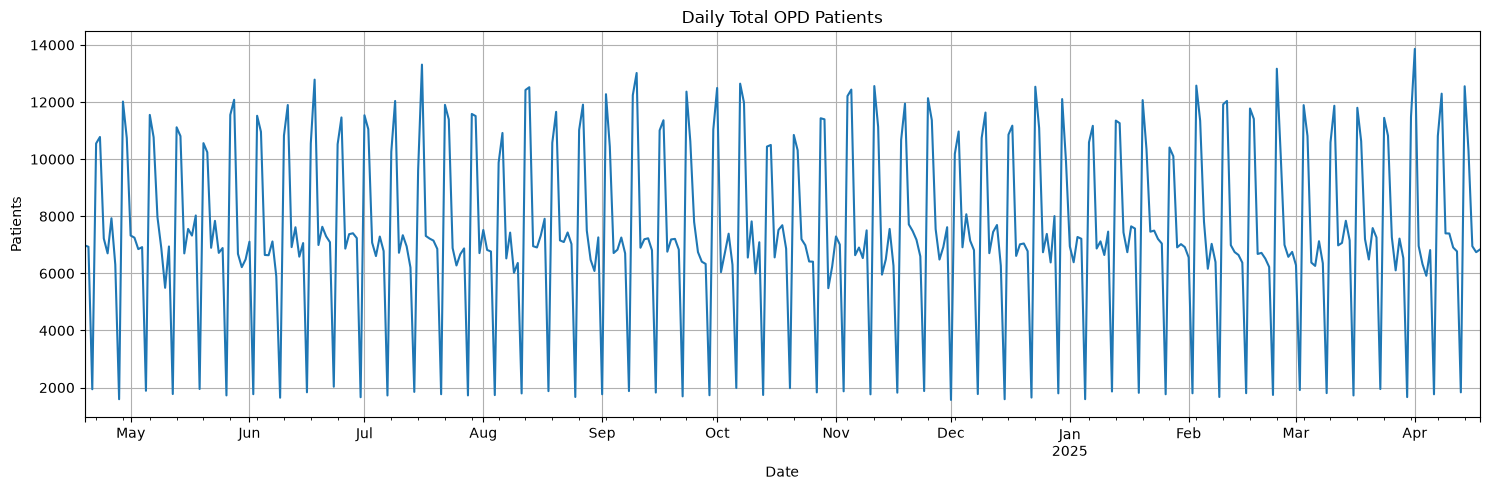

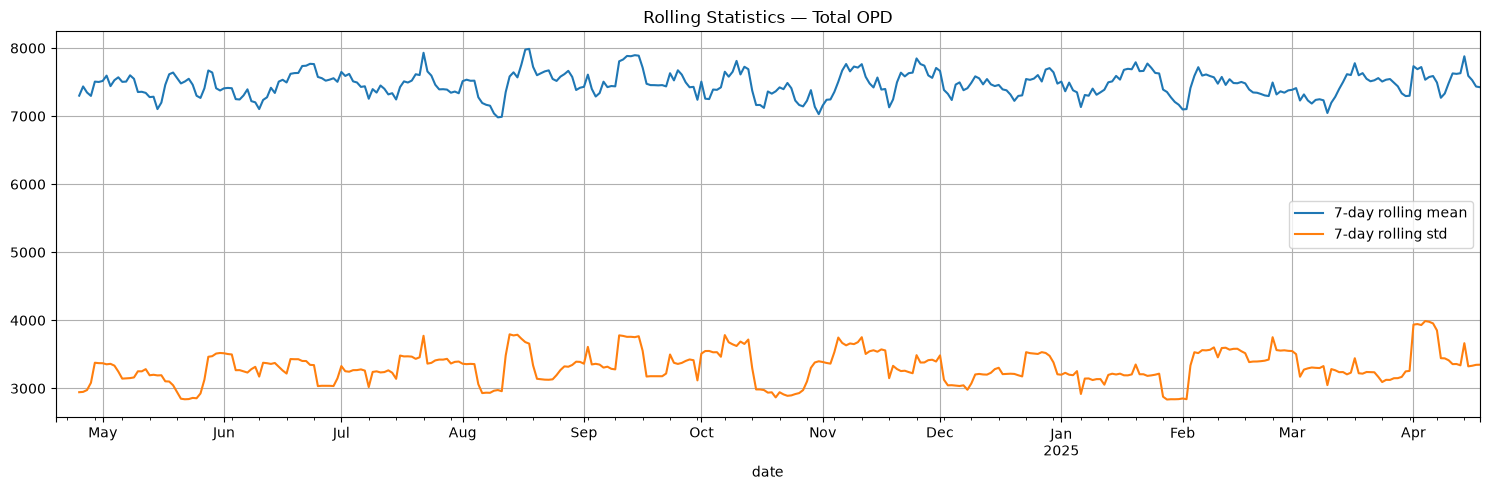

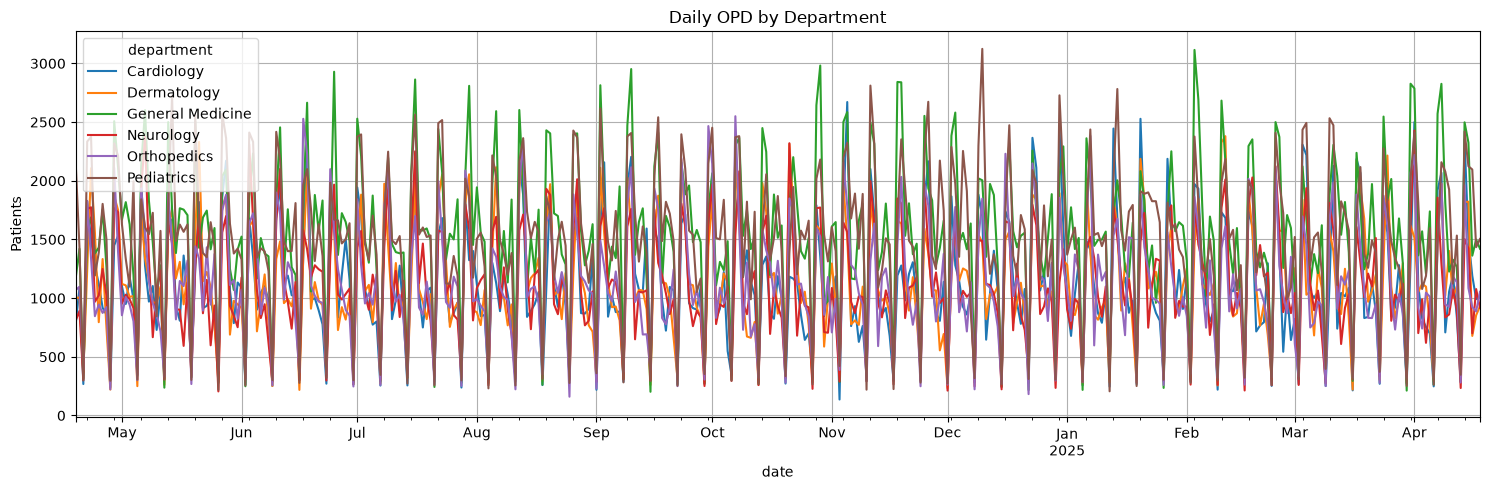

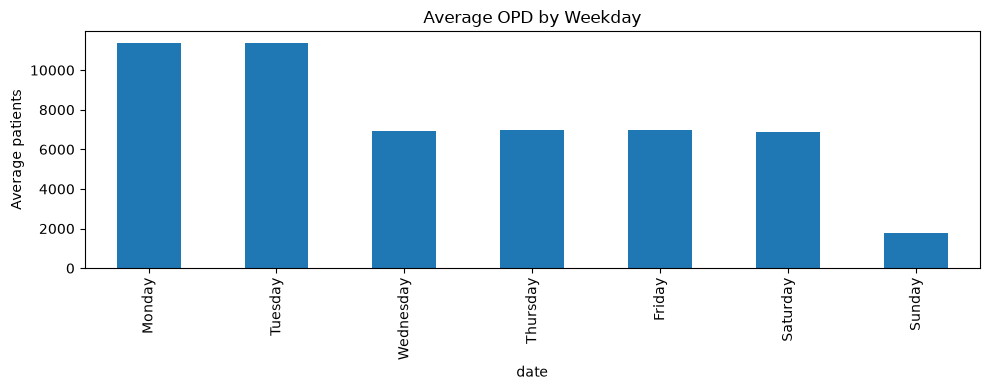

,average_patients
date,
Monday,11390.480769
Tuesday,11367.057692
Wednesday,6945.076923
Thursday,6970.480769
Friday,6969.207547
Saturday,6859.346154
Sunday,1784.826923


In [32]:
plt.figure(figsize=(15,5))
daily_total.plot()
plt.title("Daily Total OPD Patients")
plt.xlabel("Date"); plt.ylabel("Patients"); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "daily_total_trend.png", dpi=150)
plt.show()

plt.figure(figsize=(15,5))
daily_total.rolling(7).mean().plot(label="7-day rolling mean")
daily_total.rolling(7).std().plot(label="7-day rolling std")
plt.title("Rolling Statistics — Total OPD")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "rolling_statistics.png", dpi=150)
plt.show()

plt.figure(figsize=(15,5))
daily_dept.plot(ax=plt.gca())
plt.title("Daily OPD by Department")
plt.ylabel("Patients"); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "department_trends.png", dpi=150)
plt.show()

weekday_avg = daily_total.groupby(daily_total.index.day_name()).mean()
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_avg = weekday_avg.reindex(weekday_order)
weekday_avg.plot(kind="bar", figsize=(10,4), title="Average OPD by Weekday")
plt.ylabel("Average patients"); plt.tight_layout()
plt.savefig(PLOT_DIR / "weekday_pattern.png", dpi=150)
plt.show()

display(weekday_avg.to_frame("average_patients"))

,mean,median,std,min,max,sum
department,,,,,,
General Medicine,1532.358904,1531.0,665.066997,202.0,3115.0,559311.0
Pediatrics,1501.572603,1521.0,636.599938,206.0,3124.0,548074.0
Orthopedics,1121.298630,1061.0,513.380208,160.0,2550.0,409274.0
Dermatology,1113.649315,1066.0,501.381863,218.0,2380.0,406482.0
Cardiology,1106.219178,1048.0,529.828332,136.0,2671.0,403770.0
Neurology,1093.027397,1045.0,486.193026,205.0,2428.0,398955.0


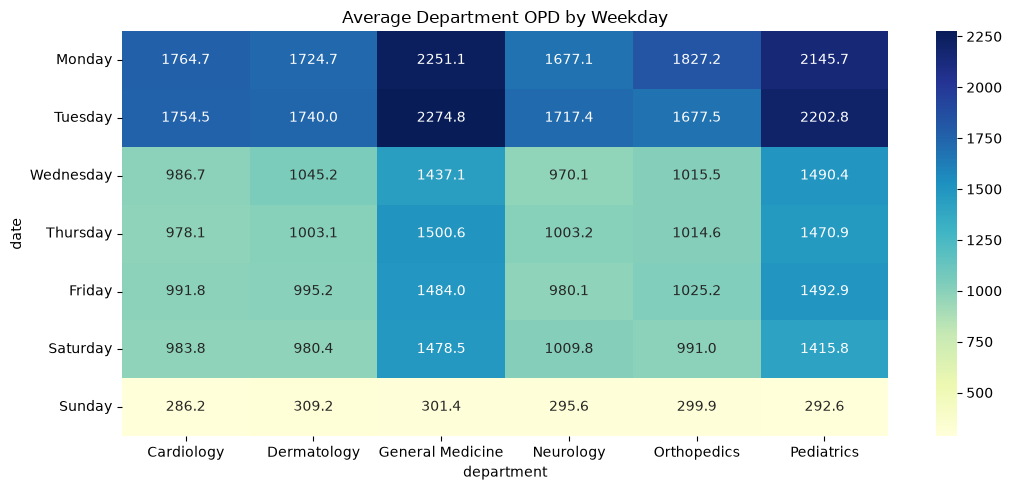

In [33]:
# Department comparison
dept_summary = daily_dept.agg(["mean", "median", "std", "min", "max", "sum"]).T
display(dept_summary.sort_values("mean", ascending=False))
dept_summary.to_csv(TABLE_DIR / "department_summary.csv")

# Weekday x department heatmap
weekday_dept = daily_dept.groupby(daily_dept.index.day_name()).mean().reindex(weekday_order)
plt.figure(figsize=(11,5))
sns.heatmap(weekday_dept, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Department OPD by Weekday")
plt.tight_layout()
plt.savefig(PLOT_DIR / "weekday_department_heatmap.png", dpi=150)
plt.show()

## 7. Time-series decomposition

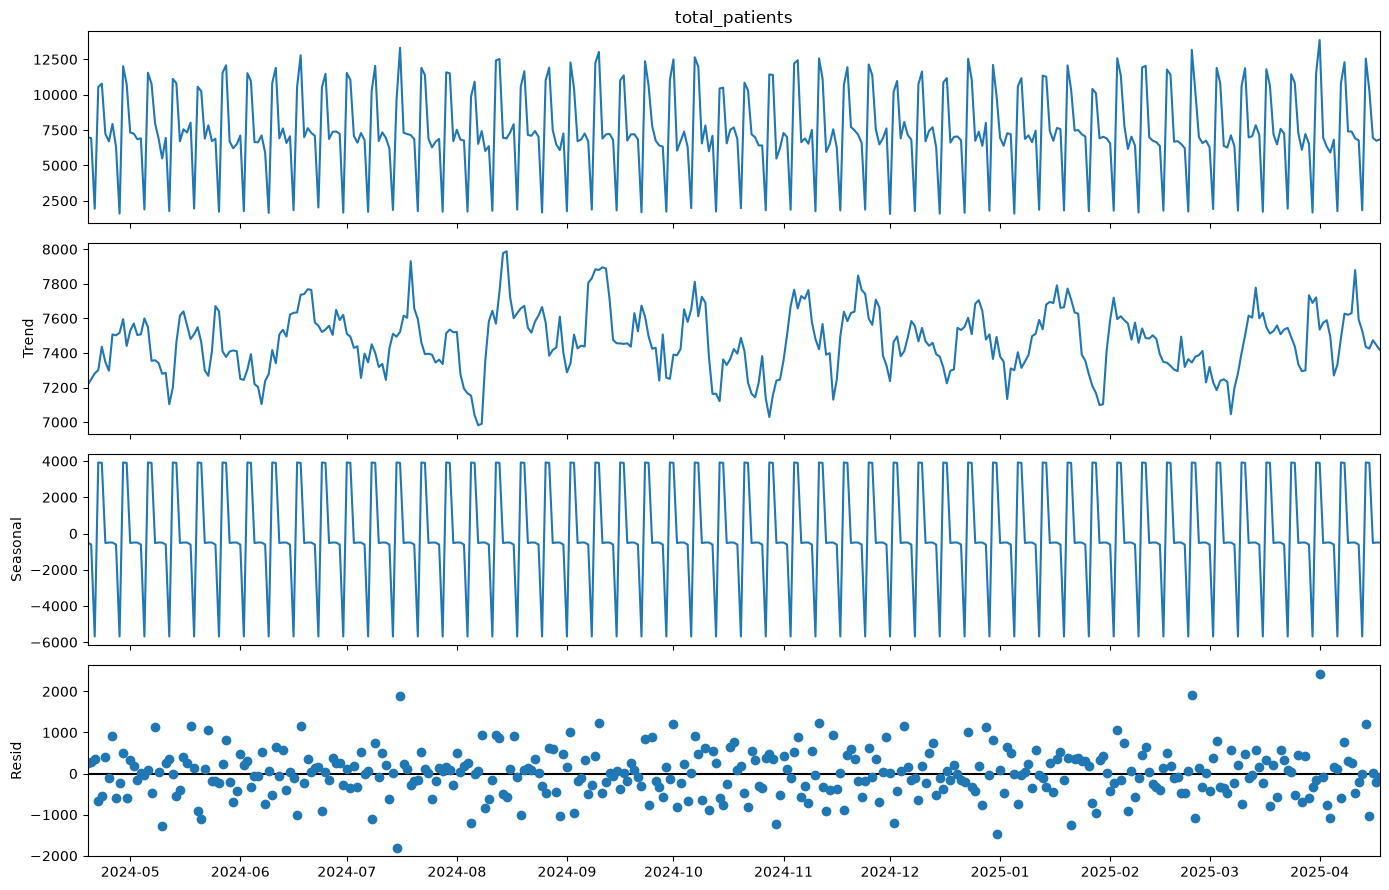

In [34]:
# Decompose the total series into trend, seasonal and residual components.
# At least two complete seasonal cycles are needed.
if len(daily_total) >= 2 * SEASONAL_PERIOD:
    decomposition = seasonal_decompose(daily_total.astype(float), model="additive",
                                       period=SEASONAL_PERIOD, extrapolate_trend="freq")
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "total_decomposition.png", dpi=150)
    plt.show()
else:
    print("Not enough observations for decomposition.")

## 8. Stationarity and model preparation
**ADF null:** the series has a unit root (non-stationary). **KPSS null:** the series is stationary around a constant. Read both p-values together and use them with the plots to explain whether differencing is reasonable. These checks inform model choices; they do not choose a model automatically.

In [35]:
def stationarity_tests(series, name="series"):
    s = pd.Series(series).dropna().astype(float)
    out = {"series": name, "n": len(s)}
    try:
        adf_result = adfuller(s, autolag="AIC")
        out["ADF_stat"], out["ADF_pvalue"] = adf_result[0], adf_result[1]
    except Exception as e:
        out["ADF_error"] = str(e)
    try:
        kpss_result = kpss(s, regression="c", nlags="auto")
        out["KPSS_stat"], out["KPSS_pvalue"] = kpss_result[0], kpss_result[1]
    except Exception as e:
        out["KPSS_error"] = str(e)
    return out

stationarity_rows = []
for name, series in {"TOTAL": daily_total, **{str(c): daily_dept[c] for c in daily_dept.columns}}.items():
    stationarity_rows.append(stationarity_tests(series, name))
    stationarity_rows.append(stationarity_tests(series.diff().dropna(), name + "_diff1"))

stationarity_df = pd.DataFrame(stationarity_rows)
display(stationarity_df)
stationarity_df.to_csv(TABLE_DIR / "stationarity_tests.csv", index=False)


,series,n,ADF_stat,ADF_pvalue,KPSS_stat,KPSS_pvalue
0,TOTAL,365,-5.517159,1.913547e-06,0.253294,0.100000
1,TOTAL_diff1,364,-11.589710,2.811182e-21,0.495576,0.042663
2,Cardiology,365,-4.235822,5.727043e-04,0.147881,0.100000
3,Cardiology_diff1,364,-12.620617,1.581228e-23,0.252477,0.100000
4,Dermatology,365,-5.166678,1.027901e-05,0.099342,0.100000
5,Dermatology_diff1,364,-11.004133,6.568915e-20,0.248382,0.100000
6,General Medicine,365,-4.510494,1.882305e-04,0.129472,0.100000
7,General Medicine_diff1,364,-10.476240,1.246919e-18,0.345823,0.100000
8,Neurology,365,-4.355963,3.548788e-04,0.112228,0.100000
9,Neurology_diff1,364,-10.631954,5.187021e-19,0.500000,0.041667


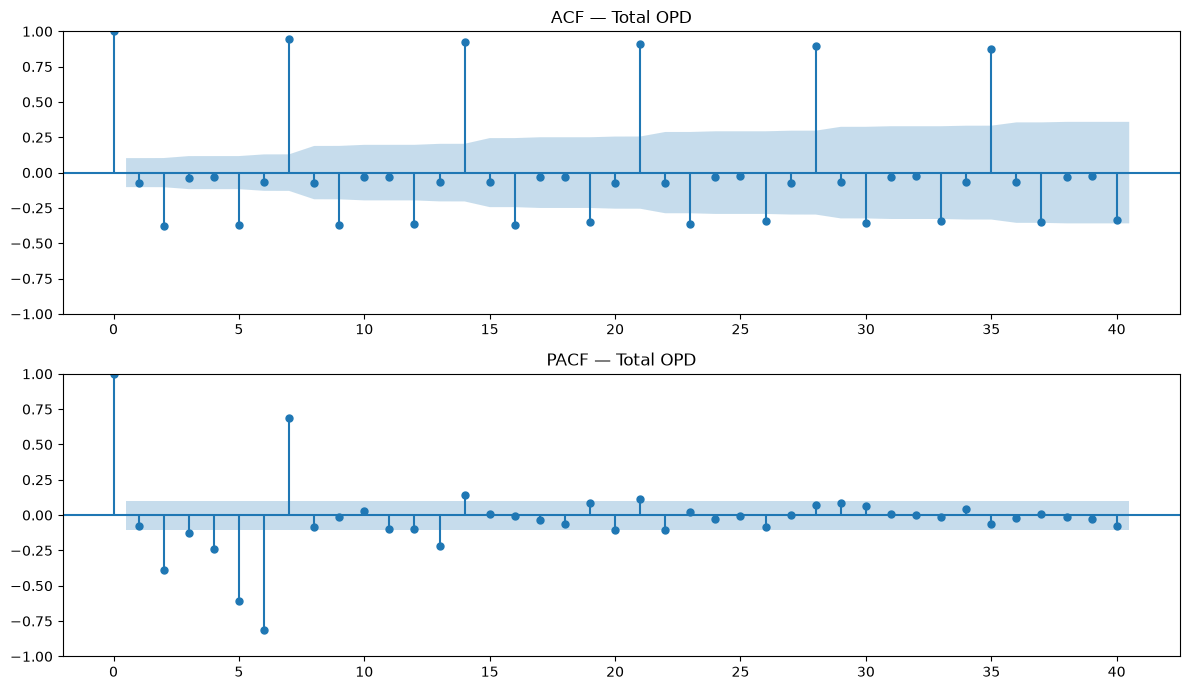

In [36]:
series_for_acf = daily_total.astype(float)
fig, axes = plt.subplots(2, 1, figsize=(12,7))
plot_acf(series_for_acf.dropna(), lags=min(40, len(series_for_acf)//2-1), ax=axes[0])
plot_pacf(series_for_acf.dropna(), lags=min(40, len(series_for_acf)//2-1), ax=axes[1], method="ywm")
axes[0].set_title("ACF — Total OPD")
axes[1].set_title("PACF — Total OPD")
plt.tight_layout()
plt.savefig(PLOT_DIR / "acf_pacf_total.png", dpi=150)
plt.show()

## 9. Chronological test period and metrics
The first 80% of dates train the models; the final 20% are held out. Each model predicts the same test dates without using actual test values. MAE and RMSE are in patient-count units. MAPE is calculated only for non-zero actuals.

In [37]:
def chronological_split(series, test_size=TEST_SIZE):
    s = pd.Series(series).astype(float).dropna()
    split = int(len(s) * (1 - test_size))
    return s.iloc[:split], s.iloc[split:]

def calculate_metrics(actual, predicted):
    actual = pd.Series(actual).astype(float)
    predicted = pd.Series(np.asarray(predicted).reshape(-1), index=actual.index).astype(float)
    valid = actual.notna() & predicted.notna()
    a, p = actual[valid], predicted[valid]
    if len(a) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "MAPE_percent": np.nan}
    mae = mean_absolute_error(a, p)
    rmse = np.sqrt(mean_squared_error(a, p))
    nonzero = a != 0
    mape = (np.mean(np.abs((a[nonzero] - p[nonzero]) / a[nonzero])) * 100
            if nonzero.any() else np.nan)
    return {"MAE": mae, "RMSE": rmse, "MAPE_percent": mape}

def seasonal_naive(train, test, period=7):
    # Fixed-origin multi-step forecast: repeat the last observed seasonal cycle.
    if len(train) < period:
        return pd.Series(np.repeat(train.iloc[-1], len(test)), index=test.index)
    last_cycle = train.iloc[-period:].to_numpy()
    preds = np.resize(last_cycle, len(test))
    return pd.Series(preds, index=test.index)

print("Evaluation helpers ready.")


Evaluation helpers ready.


## 10. Classical model comparison
We compare a naive baseline with AR, MA, ARMA, ARIMA, SARIMA, Holt-Winters, and ARIMAX. These are small candidate orders for a clear demonstration, not a full grid search:

- AR(7) uses one week of daily lags; MA(2) and ARMA(2,2) are short-memory candidates.
- ARIMA(2,1,2) includes one difference; the ADF/KPSS results help justify whether differencing is needed.
- SARIMA(1,1,1)(1,1,1,7) adds a weekly seasonal component because observations are daily.
- Additive Holt-Winters models level, trend, and weekly seasonality.
- ARIMAX(1,1,1) includes the historical holiday indicator as an external input.

The holdout metrics determine which candidate performs best on the final 20% of dates.

In [38]:
def fit_classical_models(series, series_name):
    """Fit each candidate on the training dates and score it on the same test dates."""
    train, test = chronological_split(series)
    train_holiday = holiday_daily.reindex(train.index).to_frame()
    test_holiday = holiday_daily.reindex(test.index).to_frame()
    predictions = {}
    rows = []

    def save_result(model_name, forecast):
        forecast = pd.Series(np.asarray(forecast).reshape(-1), index=test.index)
        predictions[model_name] = forecast
        rows.append({"series": series_name, "model": model_name,
                     **calculate_metrics(test, forecast)})

    # Baselines: last training value and last observed weekly pattern.
    save_result("Naive", np.repeat(train.iloc[-1], len(test)))
    save_result("SeasonalNaive_7", seasonal_naive(train, test, SEASONAL_PERIOD))

    # Candidate models. Each forecast is made from training data only.
    candidates = [
        ("AR_7", lambda: AutoReg(train, lags=7, old_names=False).fit().predict(
            start=len(train), end=len(train) + len(test) - 1)),
        ("MA_2", lambda: ARIMA(train, order=(0, 0, 2)).fit().forecast(len(test))),
        ("ARMA_2_2", lambda: ARIMA(train, order=(2, 0, 2)).fit().forecast(len(test))),
        ("ARIMA_2_1_2", lambda: ARIMA(train, order=(2, 1, 2)).fit().forecast(len(test))),
        ("SARIMA_weekly", lambda: SARIMAX(
            train, order=(1, 1, 1), seasonal_order=(1, 1, 1, SEASONAL_PERIOD),
            enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False).forecast(len(test))),
        ("Holt_Winters", lambda: ExponentialSmoothing(
            train, trend="add", seasonal="add", seasonal_periods=SEASONAL_PERIOD,
            initialization_method="estimated"
        ).fit().forecast(len(test))),
        # ARIMAX uses the known holiday flag for each date in the historical test period.
        ("ARIMAX_holiday", lambda: SARIMAX(
            train, exog=train_holiday, order=(1, 1, 1),
            enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False).forecast(len(test), exog=test_holiday)),
    ]

    for model_name, forecast_model in candidates:
        try:
            save_result(model_name, forecast_model())
        except Exception as error:
            print(f"{series_name} / {model_name} could not be fitted: {error}")

    metrics = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
    return train, test, metrics, predictions

all_series = {"TOTAL": daily_total}
all_series.update({str(department): daily_dept[department] for department in daily_dept.columns})

model_outputs = {}
metric_tables = []
for series_name, series in all_series.items():
    print("Evaluating:", series_name)
    train, test, metrics, predictions = fit_classical_models(series, series_name)
    model_outputs[series_name] = {"train": train, "test": test, "predictions": predictions}
    metric_tables.append(metrics)

classical_metrics = pd.concat(metric_tables, ignore_index=True)
display(classical_metrics.sort_values(["series", "RMSE"]))
classical_metrics.to_csv(TABLE_DIR / "classical_model_comparison.csv", index=False)

Evaluating: TOTAL
Evaluating: Cardiology
Evaluating: Dermatology
Evaluating: General Medicine
Evaluating: Neurology
Evaluating: Orthopedics
Evaluating: Pediatrics


,series,model,MAE,RMSE,MAPE_percent
9,Cardiology,Holt_Winters,196.881114,255.270996,21.644027
10,Cardiology,SARIMA_weekly,202.057846,266.294045,21.748442
11,Cardiology,SeasonalNaive_7,234.890411,282.635226,23.354761
12,Cardiology,AR_7,308.738709,414.651284,45.013234
13,Cardiology,ARIMAX_holiday,373.544315,466.207631,35.749071
...,...,...,...,...,...
4,TOTAL,ARIMAX_holiday,1959.214406,2187.331284,27.036322
5,TOTAL,ARMA_2_2,2354.115884,3127.851994,60.100760
6,TOTAL,MA_2,2363.318135,3132.785665,60.284434
7,TOTAL,ARIMA_2_1_2,2352.483477,3133.142180,60.026973


### How to explain the model comparison
AR uses past values; MA models past forecast errors; ARMA combines both; ARIMA adds differencing; SARIMA also models a repeating seasonal pattern; Holt-Winters smooths level, trend, and seasonality; ARIMAX adds an external input. Here, that input is the holiday flag known for each historical test date. The 30-day future forecast does not assume future holiday flags are available.

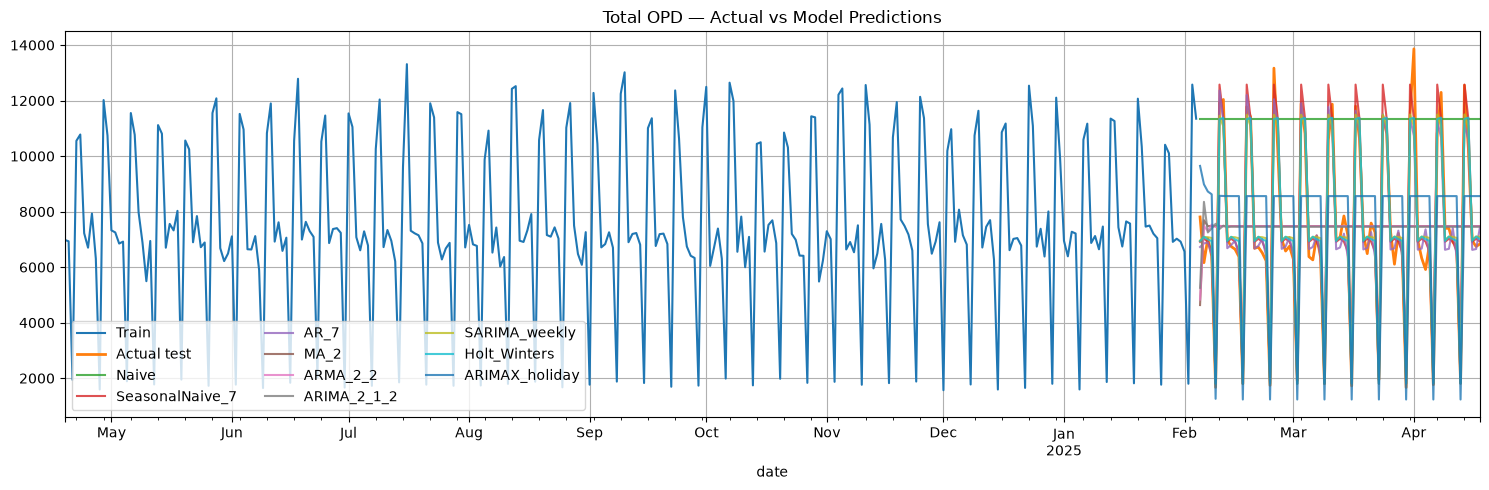

In [39]:
total_result = model_outputs["TOTAL"]
plt.figure(figsize=(15,5))
total_result["train"].plot(label="Train")
total_result["test"].plot(label="Actual test", linewidth=2)
for model_name, pred in total_result["predictions"].items():
    plt.plot(pred.index, pred.values, label=model_name, alpha=0.8)
plt.title("Total OPD — Actual vs Model Predictions")
plt.legend(ncol=3); plt.grid(True); plt.tight_layout()
plt.savefig(PLOT_DIR / "total_model_comparison.png", dpi=150)
plt.show()

## 11. Multivariate models across departments
The six departments may influence each other. **VAR** models their levels after first differencing. **VARIMA(1,1,1)** is represented by fitting a VARMA(1,1) model to the first differences and then accumulating the forecast differences back to levels. These models are reported separately; a failed fit is shown as a failure rather than a result.

In [ ]:
# Keep the same chronological split used by the univariate models.
split_at = int(len(daily_dept) * (1 - TEST_SIZE))
dept_train = daily_dept.iloc[:split_at].astype(float)
dept_test = daily_dept.iloc[split_at:].astype(float)

# VAR on first differences.
var_metrics = pd.DataFrame()
varima_metrics = pd.DataFrame()
var_rows = []
train_differences = dept_train.diff().dropna()
try:
    lag_choice = VAR(train_differences).select_order(maxlags=7).selected_orders["aic"]
    lag_choice = max(1, int(lag_choice or 1))
    var_fit = VAR(train_differences).fit(lag_choice)
    predicted_differences = pd.DataFrame(
        var_fit.forecast(train_differences.values[-lag_choice:], steps=len(dept_test)),
        index=dept_test.index, columns=dept_test.columns
    )
    var_levels = predicted_differences.cumsum().add(dept_train.iloc[-1], axis="columns")
    for department in dept_test.columns:
        var_rows.append({"series": department, "model": f"VAR_diff_lag{lag_choice}",
                         **calculate_metrics(dept_test[department], var_levels[department])})
    var_metrics = pd.DataFrame(var_rows)
    display(var_metrics)
    var_levels.to_csv(FORECAST_DIR / "var_department_test_forecast.csv")
except Exception as error:
    print("VAR fit failed:", error)

# VARIMA(1,1,1): first-difference the data, fit VARMA(1,1), then integrate forecasts.
try:
    varima_fit = VARMAX(train_differences, order=(1, 1), trend="c").fit(
        disp=False, maxiter=100
    )
    varima_differences = varima_fit.forecast(steps=len(dept_test))
    varima_levels = varima_differences.cumsum().add(dept_train.iloc[-1], axis="columns")
    varima_rows = []
    for department in dept_test.columns:
        varima_rows.append({"series": department, "model": "VARIMA_1_1_1",
                            **calculate_metrics(dept_test[department], varima_levels[department])})
    varima_metrics = pd.DataFrame(varima_rows)
    display(varima_metrics)
    varima_levels.to_csv(FORECAST_DIR / "varima_department_test_forecast.csv")
except Exception as error:
    print("VARIMA(1,1,1) fit failed:", error)


,series,model,MAE,RMSE,MAPE_percent
0,Cardiology,VAR_diff_lag7,258.828764,313.982022,39.600851
1,Dermatology,VAR_diff_lag7,209.384694,268.986410,24.525411
2,General Medicine,VAR_diff_lag7,362.723706,421.402100,44.723932
3,Neurology,VAR_diff_lag7,190.725114,257.619165,19.890706
4,Orthopedics,VAR_diff_lag7,174.954750,227.777282,19.493670
5,Pediatrics,VAR_diff_lag7,254.441474,321.735011,19.775848


## 12. Thirty-day forecast
For the future forecast, compare ARIMA, weekly SARIMA, and Holt-Winters by their RMSE on the same holdout. Refit the lowest-RMSE candidate on all observed dates, then forecast 30 days ahead. We do not use ARIMAX for the future forecast because future holiday inputs have not been supplied.

In [ ]:
def fit_best_and_forecast(series, horizon=FORECAST_HORIZON):
    s = pd.Series(series).astype(float).dropna()
    train, test = chronological_split(s)
    candidate_builders = {
        "ARIMA_2_1_2": lambda x: ARIMA(x, order=(2,1,2)).fit(),
        "SARIMA_weekly": lambda x: SARIMAX(x, order=(1,1,1),
            seasonal_order=(1,1,1,SEASONAL_PERIOD), enforce_stationarity=False,
            enforce_invertibility=False).fit(disp=False),
        "Holt_Winters": lambda x: ExponentialSmoothing(
            x, trend="add", seasonal="add" if len(x) >= 2*SEASONAL_PERIOD else None,
            seasonal_periods=SEASONAL_PERIOD if len(x) >= 2*SEASONAL_PERIOD else None,
            initialization_method="estimated").fit(optimized=True),
    }
    scored = []
    for name, builder in candidate_builders.items():
        try:
            fitted = builder(train)
            pred = pd.Series(np.asarray(fitted.forecast(len(test))).reshape(-1), index=test.index)
            scored.append((name, calculate_metrics(test, pred)["RMSE"]))
        except Exception as e:
            print(name, "holdout fit failed:", e)
    if not scored:
        raise RuntimeError("No candidate model fitted successfully on the training period.")
    best_name, best_rmse = min(scored, key=lambda item: item[1])
    final_fit = candidate_builders[best_name](s)
    forecast = pd.Series(np.asarray(final_fit.forecast(horizon)).reshape(-1),
                         index=pd.date_range(s.index[-1] + pd.Timedelta(days=1),
                                             periods=horizon, freq="D"))
    return best_name, best_rmse, forecast

future_forecasts = {}
future_summary = []
for name, series in all_series.items():
    try:
        best_name, holdout_rmse, fc = fit_best_and_forecast(series)
        future_forecasts[name] = fc
        future_summary.append({"series": name, "selected_model_by_holdout_RMSE": best_name,
                              "holdout_RMSE": holdout_rmse})
        fc.to_frame("forecast").to_csv(FORECAST_DIR / f"{name.lower()}_future_forecast.csv")
    except Exception as e:
        print(name, "future forecast failed:", e)

future_selection_df = pd.DataFrame(future_summary)
display(future_selection_df)
future_selection_df.to_csv(TABLE_DIR / "future_model_selection.csv", index=False)


In [ ]:
if "TOTAL" in future_forecasts:
    plt.figure(figsize=(14,5))
    daily_total.tail(90).plot(label="Recent actual")
    future_forecasts["TOTAL"].plot(label="Future forecast")
    plt.title(f"Total OPD — next {FORECAST_HORIZON} days")
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.savefig(PLOT_DIR / "total_future_forecast.png", dpi=150)
    plt.show()

## 13. Supplemental libraries and AutoTS
This section retains the project?s library deliverables. **TSFresh** extracts time-series features; it is not itself a forecasting model. **Prophet** and **Darts** provide additional forecast examples. **AutoTS** performs automatic model search and is included as a required supplemental library. Report results only when the corresponding run completed.

In [ ]:
# TSFresh optional feature extraction
if importlib.util.find_spec("tsfresh") is None:
    print("TSFresh not installed. Install with: %pip install tsfresh")
else:
    from tsfresh import extract_features
    tsfresh_input = daily_dept.reset_index().melt(id_vars="date", var_name="department", value_name="value")
    tsfresh_input["id"] = tsfresh_input["department"]
    tsfresh_input = tsfresh_input.rename(columns={"date": "time"})
    try:
        tsfresh_features = extract_features(tsfresh_input[["id","time","value"]],
                                            column_id="id", column_sort="time",
                                            disable_progressbar=True)
        display(tsfresh_features.head())
        tsfresh_features.to_csv(TABLE_DIR / "tsfresh_department_features.csv")
    except Exception as e:
        print("TSFresh extraction failed:", repr(e))

In [ ]:
# Prophet optional — total OPD
if importlib.util.find_spec("prophet") is None:
    print("Prophet not installed. Install with: %pip install prophet")
else:
    from prophet import Prophet
    prophet_df = daily_total.rename_axis("ds").reset_index(name="y")
    try:
        prophet_model = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False)
        prophet_model.fit(prophet_df)
        future = prophet_model.make_future_dataframe(periods=FORECAST_HORIZON, freq="D")
        prophet_forecast = prophet_model.predict(future)
        prophet_forecast.tail(FORECAST_HORIZON).to_csv(FORECAST_DIR / "prophet_total_forecast.csv", index=False)
        fig = prophet_model.plot(prophet_forecast)
        plt.tight_layout(); plt.savefig(PLOT_DIR / "prophet_total_forecast.png", dpi=150); plt.show()
    except Exception as e:
        print("Prophet failed:", repr(e))

In [ ]:
# Darts optional — total OPD
if importlib.util.find_spec("darts") is None:
    print("Darts not installed. Install with: %pip install 'u8darts[all]'")
else:
    try:
        from darts import TimeSeries
        from darts.models import ExponentialSmoothing as DartsExponentialSmoothing
        ts = TimeSeries.from_series(daily_total.astype(float))
        darts_model = DartsExponentialSmoothing()
        darts_model.fit(ts)
        darts_forecast = darts_model.predict(FORECAST_HORIZON)
        # Current Darts releases expose to_dataframe(); older releases may expose pd_dataframe().
        if hasattr(darts_forecast, "to_dataframe"):
            darts_forecast_df = darts_forecast.to_dataframe()
        elif hasattr(darts_forecast, "pd_dataframe"):
            darts_forecast_df = darts_forecast.pd_dataframe()
        else:
            raise AttributeError("This Darts TimeSeries version has no supported dataframe conversion method.")
        darts_forecast_df.to_csv(FORECAST_DIR / "darts_total_forecast.csv")
        display(darts_forecast_df.head())
    except Exception as e:
        print("Darts workflow failed:", repr(e))

In [ ]:
# AutoTS optional — run independently for each series.
# For initial testing, run TOTAL only. Increase to all departments after validating.
if importlib.util.find_spec("autots") is None:
    print("AutoTS not installed. Install with: %pip install autots")
else:
    from autots import AutoTS
    autots_outputs = []
    targets_to_run = {"TOTAL": daily_total}  # change to all_series to run all 7 targets
    for name, series in targets_to_run.items():
        auto_df = series.rename("value").rename_axis("date").reset_index()
        try:
            auto_model = AutoTS(
                forecast_length=FORECAST_HORIZON,
                frequency="D",
                prediction_interval=0.90,
                ensemble=None,
                model_list="fast",
                transformer_list="fast",
                max_generations=2,
                num_validations=2,
                validation_method="backwards",
                n_jobs="auto"
            )
            auto_model = auto_model.fit(auto_df, date_col="date", value_col="value")
            auto_prediction = auto_model.predict()
            auto_forecast = auto_prediction.forecast
            if not np.isfinite(auto_forecast.to_numpy(dtype=float)).all():
                raise ValueError("AutoTS returned NaN or infinite forecast values.")
            auto_forecast.to_csv(FORECAST_DIR / f"autots_{name.lower()}_forecast.csv")
            auto_model.best_model.to_csv(TABLE_DIR / f"autots_{name.lower()}_best_model.csv", index=False)
            autots_outputs.append({"series": name, "forecast_rows": len(auto_forecast),
                                   "best_model": str(auto_model.best_model.get("Model", ["unknown"]).iloc[0])})
            print(name, "AutoTS completed.")
        except Exception as e:
            print(name, "AutoTS failed:", repr(e))
    display(pd.DataFrame(autots_outputs))

## 14. Final model comparison
The table combines the classical holdout metrics with department-level VAR/VARIMA metrics when those models fit. The best row for each series is selected by RMSE. AutoTS is shown separately because its built-in validation setup differs from this notebook?s fixed holdout.

In [ ]:
# Start with the classical holdout results.
comparison_parts = [classical_metrics.copy()]

# Add a multivariate model only if that model fitted successfully.
if "var_metrics" in globals() and not var_metrics.empty:
    comparison_parts.append(var_metrics.copy())
if "varima_metrics" in globals() and not varima_metrics.empty:
    comparison_parts.append(varima_metrics.copy())

final_comparison = pd.concat(comparison_parts, ignore_index=True, sort=False)
final_comparison = final_comparison.sort_values(["series", "RMSE"])
display(final_comparison)
final_comparison.to_csv(TABLE_DIR / "final_model_comparison.csv", index=False)

best_by_series = final_comparison.loc[
    final_comparison.groupby("series")["RMSE"].idxmin()
].reset_index(drop=True)
display(best_by_series)
best_by_series.to_csv(TABLE_DIR / "best_model_by_series.csv", index=False)

## 15. Interpretation and residual check
Use the table and plots to report the best total-series model, its MAE/RMSE/MAPE, and how it compares with the naive baseline. Describe one weekday or department pattern and connect it to a practical planning decision. Mention that the dataset covers one year, so it cannot represent longer-term annual changes.

In [ ]:
best_total = best_by_series.loc[best_by_series["series"] == "TOTAL"].iloc[0]
total_test_result = model_outputs["TOTAL"]
best_total_prediction = total_test_result["predictions"][best_total["model"]]
total_residuals = total_test_result["test"] - best_total_prediction
print(f"Total OPD best holdout model: {best_total['model']}")
print(f"MAE={best_total['MAE']:.2f}, RMSE={best_total['RMSE']:.2f}, MAPE={best_total['MAPE_percent']:.2f}%")
naive_total = final_comparison[(final_comparison["series"] == "TOTAL") & (final_comparison["model"] == "Naive")]
if not naive_total.empty:
    print(f"Naive baseline RMSE={naive_total.iloc[0]['RMSE']:.2f}")
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
total_residuals.plot(ax=axes[0], title="Total OPD holdout residuals over time")
axes[0].axhline(0, color="black", linewidth=1); axes[0].grid(True)
sns.histplot(total_residuals, kde=True, ax=axes[1])
axes[1].set_title("Distribution of total OPD holdout residuals")
plt.tight_layout(); plt.show()


### Short presentation script
After running the notebook, complete this summary in your own words: ?For total OPD, **[model]** had the lowest holdout RMSE (**[value]**) and MAE/MAPE of **[values]**. Compared with the naive baseline, this means **[finding]** on the held-out dates. The plots show **[pattern]**, which could help the hospital **[planning use]**. A limitation is **[limitation]**.?

## 16. Export a compact project report

In [ ]:
report_lines = [
    "# Hospital OPD Time Series Analysis — Run Summary",
    f"- Data rows after cleaning: {len(df)}",
    f"- Daily observations: {len(daily_total)}",
    f"- Date range: {daily_total.index.min().date()} to {daily_total.index.max().date()}",
    f"- Departments: {', '.join(map(str, daily_dept.columns))}",
    f"- Forecast horizon: {FORECAST_HORIZON} days",
    "",
    "## Best classical/VAR model by RMSE",
]
for _, row in best_by_series.iterrows():
    report_lines.append(
        f"- {row['series']}: {row['model']} | MAE={row['MAE']:.3f} | "
        f"RMSE={row['RMSE']:.3f} | MAPE={row['MAPE_percent']:.3f}%"
    )
(OUTPUT_DIR / "run_summary.md").write_text("\n".join(report_lines), encoding="utf-8")
print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Summary:", (OUTPUT_DIR / "run_summary.md").resolve())

## 17. Notebook presentation checklist
- Confirm the patient-count aggregation and missing-date assumption with the dataset source.
- Investigate the reported duplicate rows; do not delete them without domain confirmation.
- Show the chronological train/test dates and compare MAE, RMSE, and MAPE.
- Describe VAR as differenced VAR if it completes; do not call it VARIMA.
- Describe SARIMAX without regressors as a no-exogenous baseline, not ARIMAX.
- Report optional-library models only when they completed and produced valid output.
